# **The Core**

At the base of the ISA system is the core, a selection of ETFs that are held 100% of the times that are not defensive/rebound.

## Imports

In [1]:
import sys
from pathlib import Path
here = Path.cwd()
src = next(c for p in [here, *here.parents]
           for c in (p / "src", p / "isa_showcase" / "src", p / "isa_portfolio" / "isa_showcase" / "src",
                     p / "trading_portfolio" / "isa_portfolio" / "isa_showcase" / "src")
           if (c / "showcase_plots.py").exists())
sys.path.insert(0, str(src))
import pandas as pd
import showcase_plots as sp
sp.style()
d = sp.monthly()

## Summary

The core consists of 3 ETFs, iShares Edge MSCI World Minimum Volatility UCITS ETF (MINV), iShares Edge MSCI World Quality Factor UCITS ETF (IWFQ), iShares Edge MSCI World Momentum Factor(IWFM), all tracking MSCI Minimum volatility, MSCI Neutral quality, MSCI Momentum indices respectively. This core was chosen over VWRP due to its theoretical advantage during tough economic times, alongside momentum tending to perform well in trends, and minumum volatility and quality performing better in sell-offs.

In [2]:
sp.table("layers_stats.csv").query("layers == 'core'").drop(columns="layers").set_index("window")

,months,sharpe,cagr_pct,vol_pct,max_drawdown_pct,final_gbp_from_10k
window,,,,,,
full 2001-02–2026-09,308,0.560,8.694,11.997,-35.707,"84,969.957"
book 2006-01–2026-09,249,0.759,10.515,11.606,-25.970,"79,608.623"
2001-05,59,-0.160,1.334,13.329,-35.707,"10,673.461"
2006-13,96,0.438,7.293,13.004,-25.970,"17,561.313"
2014-19,72,1.330,14.319,10.115,-10.105,"22,321.074"
2020-26,81,0.755,11.067,11.106,-11.439,"20,308.976"


See on average the core returns ~10% a year post 2001-recession without defensive handling. This acts as our baseline market exposure for the sleeves/overlay to take cash out of.

## Growth and drawdown

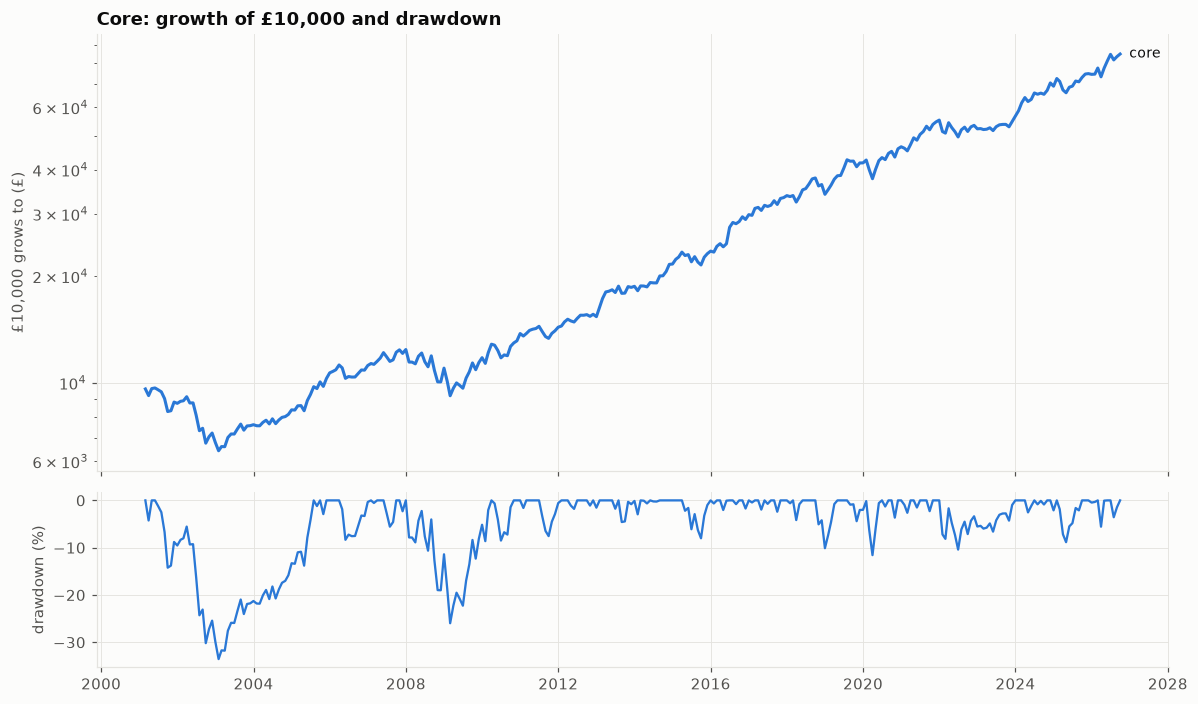

In [3]:
sp.curves({"core": d["core"]}, sp.COLORS, "Core: growth of £10,000 and drawdown")

The core performs steadily well outside of primarily 2001-2003, and 2008-2009 recessions, with downward spikes in 2020, 2022 due to the COVID pandemic and rates spike crisis respectively. This can also be seen on the rolling Sharpe plot below, with the main drops being due to recessions, same as above.

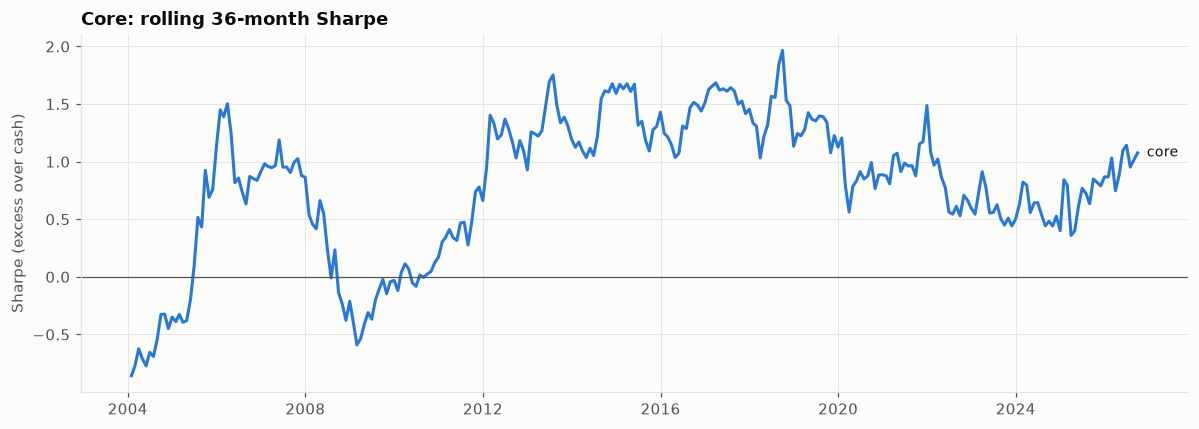

In [4]:
sp.lines({"core": sp.rolling_sharpe(d["core"], d["cash"])}, sp.COLORS, "Core: rolling 36-month Sharpe", "Sharpe (excess over cash)")